# SpaceJEPA v3 · 3. Analysis and report

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rk0604/ReEntryAI/blob/jepa-v3/StochasticEntrySim/ReEntryAI_JEPA_v3_3_analyze.ipynb)

**Runtime: CPU with High-RAM** (it opens that way; nothing here uses a GPU, so a GPU only costs credits).
It takes roughly 30–60 min and releases the runtime by itself when it finishes.

Reads the flights and checkpoints from Drive and writes:
* `03_open_loop/`: footprint error, along-track bias, and ensemble spread per model and seed, on the
  held-out test flights;
* `05_analysis/tables/T##_*.csv` and `figures/F##_*.png`, with `captions.json` saying what each shows
  and which file its data came from;
* `06_report/SpaceJEPA_v3_report.pdf`.

The statistics follow `v3_plan.md` §8, fixed before any v3 flight:
* paired by condition (same IC and the same MPPI noise stream);
* a hierarchical bootstrap with 10,000 resamples (seeds, then cases within each atmosphere);
* per-seed exact McNemar and sign tests;
* Holm correction over the hypothesis-test criteria;
* criteria C1–C7 and the Bridge check.

It can run at any point. With only some seeds finished, it reports those.

## 0. Setup

On Colab this clones the `jepa-v3` branch, installs `pymsis`, and mounts Google Drive. Every output
goes to **`MyDrive/ReEntryAI_jepa_v3/`** (`ReEntryAI_jepa_v3_smoke/` in smoke mode); the layout is in
`jepa/v3_plan.md` §9 and in the auto-written `00_study/README.md`. The 6,000 flights are read from
`MyDrive/ReEntryAI_jepa_data/wide_6000/`. Every stage is resumable: after a disconnect, run all
cells again and finished work is skipped.

In [ ]:
%pip install -q reportlab

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
BRANCH = "jepa-v3"
MODE = os.environ.get("JEPA_V3_MODE", "full")     # "full": the study | "smoke": every stage, tiny, numbers meaningless
if IN_COLAB:
    REPO = "/content/ReEntryAI"
    if not os.path.exists(REPO):
        !git clone -q -b {BRANCH} https://github.com/rk0604/ReEntryAI.git {REPO}
    else:
        !git -C {REPO} pull -q
    %pip install -q pymsis
    os.chdir(f"{REPO}/StochasticEntrySim")
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = "/content/drive/MyDrive"
    STUDY_ROOT = f"{DRIVE}/ReEntryAI_jepa_v3" + ("" if MODE == "full" else f"_{MODE}")
    DATA_CANDIDATES = [f"{DRIVE}/ReEntryAI_jepa_data/wide_6000/episodes_wide_6000.pkl",
                       f"{DRIVE}/ReEntryAI_jepa_data/wide_6000"]
    LOCAL_DATA = "/content/data"
else:
    STUDY_ROOT = os.environ.get("JEPA_V3_ROOT", f"jepa_runs/v3_{MODE}")
    DATA_CANDIDATES = [os.environ.get("JEPA_WIDE_DATA", ""), "jepa_runs/episodes_wide_6000.pkl", "jepa_runs/wide_6000"]
    LOCAL_DATA = "jepa_runs"

import time
from pathlib import Path
SIM_DIR = Path.cwd()
assert (SIM_DIR / "rl_env.py").exists(), "start Jupyter in StochasticEntrySim/"
sys.path.insert(0, str(SIM_DIR))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline
from jepa import testset_v3 as TS, study_v3 as S, fly_v3 as F, analyze_v3 as A

CFG = S.StudyConfig.smoke() if MODE == "smoke" else S.StudyConfig()
L = S.Layout(STUDY_ROOT).make()
FROZEN = S.freeze_config(CFG, L)
CPUS = os.cpu_count() or 2
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"MODE={MODE}  study folder={STUDY_ROOT}  device={DEVICE}  cpus={CPUS}  git={FROZEN['git_commit'][:10]}")

# ---- Auto-disconnect: stop paying for the runtime once the work is done or a cell fails ----
AUTO_DISCONNECT = IN_COLAB      # set to False to keep the runtime (e.g. to explore results by hand)

def release_runtime(reason):
    # Flush Drive, then release the Colab runtime so it stops using compute units.
    if not (IN_COLAB and AUTO_DISCONNECT):
        print(f"[auto-disconnect off] {reason}")
        return
    print(f"[auto-disconnect] {reason}. Flushing Drive and releasing the runtime; outputs stay visible.", flush=True)
    try:
        drive.flush_and_unmount()
    except Exception as e:
        print("  Drive flush:", e)
    from google.colab import runtime
    runtime.unassign()

def _release_on_error(result):
    err = result.error_in_exec or result.error_before_exec
    if err is not None and not isinstance(err, KeyboardInterrupt):     # pressing stop is not a failure
        release_runtime(f"a cell failed ({type(err).__name__}: {str(err)[:200]})")

_ip = get_ipython()
for _cb in list(_ip.events.callbacks["post_run_cell"]):
    if getattr(_cb, "__name__", "") == "_release_on_error":
        _ip.events.unregister("post_run_cell", _cb)
_ip.events.register("post_run_cell", _release_on_error)
print("auto-disconnect on: the runtime is released when the last cell finishes or a cell fails" if AUTO_DISCONNECT
      else "auto-disconnect off (not on Colab, or switched off): the runtime stays up until you disconnect it")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 17.4 MB/s eta 0:00:00
Mounted at /content/drive
MODE=full  study folder=/content/drive/MyDrive/ReEntryAI_jepa_v3  device=cpu  cpus=8  git=f0094aa6ca
auto-disconnect on: the runtime is released when the last cell finishes or a cell fails


## 1. Open loop, per model and seed (cached as CSV)

600 held-out test flights
  v1 seed 0: 2s
  v2 seed 0: 207s
  v1 seed 1: 2s
  v2 seed 1: 203s
  v1 seed 2: 2s
  v2 seed 2: 201s
  v1 seed 3: 2s
  v2 seed 3: 205s
  v1 seed 4: 2s
  v2 seed 4: 201s


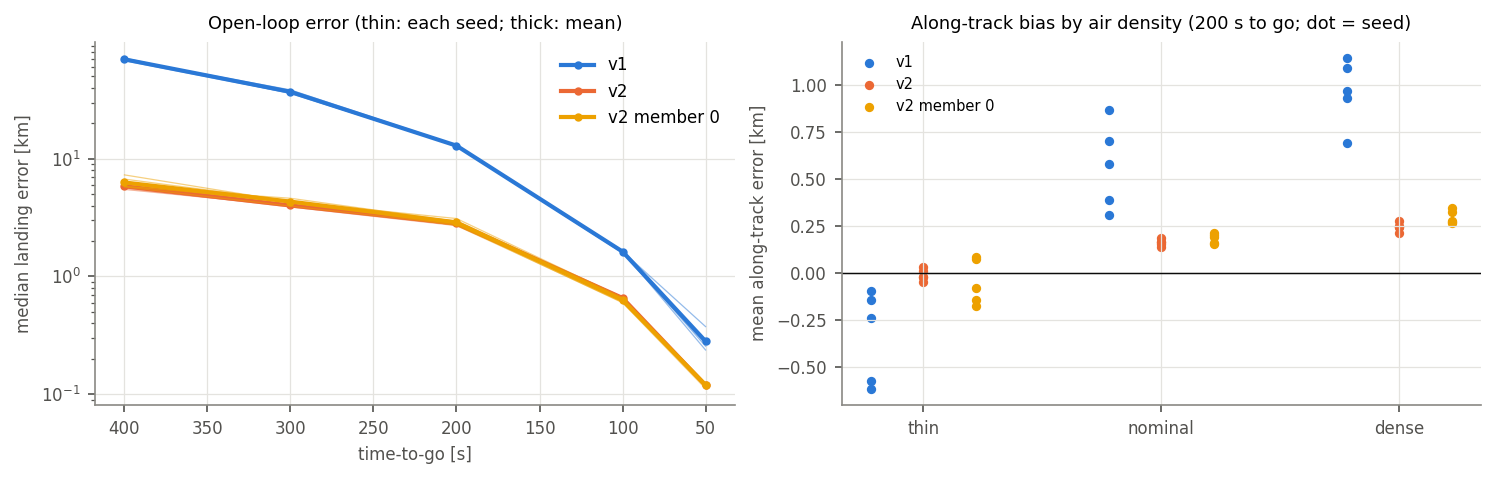

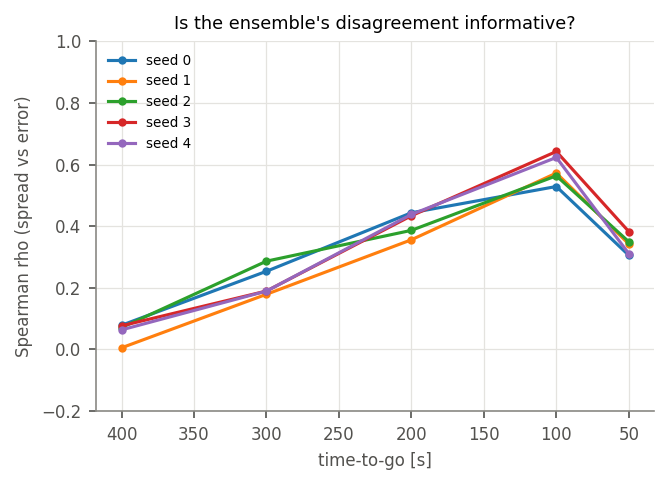

In [2]:
from jepa import train_v2 as T2
try:
    DATA_PATH = T2.local_copy(T2.find_wide_dataset(DATA_CANDIDATES, download_dir=LOCAL_DATA), LOCAL_DATA)
    test_eps = A.test_split(CFG, DATA_PATH)
    print(f"{len(test_eps)} held-out test flights")
    for seed in CFG.seeds:
        for kind in ("v1", "v2"):
            t0 = time.time()
            if A.open_loop_seed(CFG, L, test_eps, kind, seed) is not None:
                print(f"  {kind} seed {seed}: {time.time() - t0:.0f}s")
except FileNotFoundError as e:
    print("open loop skipped:", e)
OL = A.open_loop_summary(CFG, L)
for k in ("F30", "F31"):
    if k in OL:
        display(Image(str(OL[k])))

## 2. Closed loop: tables, statistics, criteria, figures

In [3]:
if not (L.testset / "F01_testset_coverage.png").exists():
    A.testset_figures(L, pd.read_csv(SIM_DIR / CFG.testset_csv), pd.read_csv(SIM_DIR / "configs/v3_testset_footprints.csv"))
t0 = time.time()
R = A.analyze(CFG, L)
print(f"analysis of {R.get('n_flights', 0)} flights, seeds {R.get('seeds')}, in {time.time() - t0:.0f}s")
if R:
    pd.set_option("display.max_colwidth", 120)
    display(R["T05"][["id", "question", "measured", "p_holm", "met"]])

analysis of 5120 flights, seeds [0, 1, 2, 3, 4], in 2675s


,id,question,measured,p_holm,met
0,C1,Is v2 better than v1 at an equal budget?,"success@5km +59.5 pp [+54.9, +63.9], holds in 5/5 seeds",0.0003,True
1,C2,Does v2 beat the classical controller?,"success@5km +54.1 pp [+48.9, +59.0], holds in 5/5 seeds; classical significantly better in: none",0.0003,True
2,C3,Is the comparison really load-matched?,"v2 − classical mean peak g: nominal +0.50, thin ×0.88 +0.37, dense ×1.12 +0.56, ×0.78 / L/D ×0.80 +0.18",NaN,False
3,C4,"Does v2 reach the goal (≥ 90% within 5 km, feasible conditions)?","nominal 99.0%, thin ×0.88 100.0%, dense ×1.12 98.4%, ×0.78 / L/D ×0.80 100.0%",NaN,True
4,C5,Is v2 no worse on heating (median paired ratio ≤ 1.10)?,"peak heat rate ratio 0.986, heat load ratio 1.010",NaN,True
5,C6,Is v2 stable across seeds (success@5km range ≤ 10 pp)?,"nominal 1.6 pp, thin ×0.88 0.0 pp, dense ×1.12 0.0 pp, ×0.78 / L/D ×0.80 0.0 pp",NaN,True
6,C7,Does the ensemble matter (secondary)?,"v2 − single member success@5km -0.1 pp [-0.5, +0.0]",1.0000,False
7,Bridge,"Does v3 reproduce v2's first run (seed 0, 8 g, 16 bridge cases)?","nominal 1.23 vs 0.90 km, thin ×0.88 1.24 vs 1.29 km, dense ×1.12 1.76 vs 1.89 km, ×0.78 / L/D ×0.80 2.22 vs 2.42 km",NaN,True


,controller,atmosphere,n_seeds,success5_%,success5_%_min,success5_%_max,miss_median_km,miss_p90_km,peak_g_mean,peak_qdot_MWm2_mean,heat_load_MJm2_mean,rcs_fuel_kg_mean
0,classical,mismatch,1,21.88,21.88,21.88,10.49,20.74,3.75,0.49,71.04,51.09
1,classical,mismatch_high,1,90.62,90.62,90.62,1.69,4.68,3.53,0.43,64.49,89.63
2,classical,nominal,1,51.56,51.56,51.56,4.52,15.61,3.60,0.46,67.50,69.27
3,classical,out_of_range,1,6.25,6.25,6.25,23.94,43.45,3.90,0.52,74.54,43.04
4,v1,mismatch,5,29.69,17.19,39.06,12.61,49.57,3.94,0.50,70.45,40.42
5,v1,mismatch_high,5,26.25,9.38,37.50,7.95,10.94,4.03,0.44,63.75,44.89
6,v1,nominal,5,85.94,73.44,92.19,2.11,7.87,3.95,0.47,66.91,43.30
7,v1,out_of_range,5,6.56,4.69,9.38,31.06,104.69,3.95,0.53,74.08,38.76
8,v2,mismatch,5,98.44,98.44,98.44,1.56,2.49,4.12,0.48,72.16,40.60
9,v2,mismatch_high,5,98.44,98.44,98.44,1.92,2.71,4.09,0.44,63.82,42.29


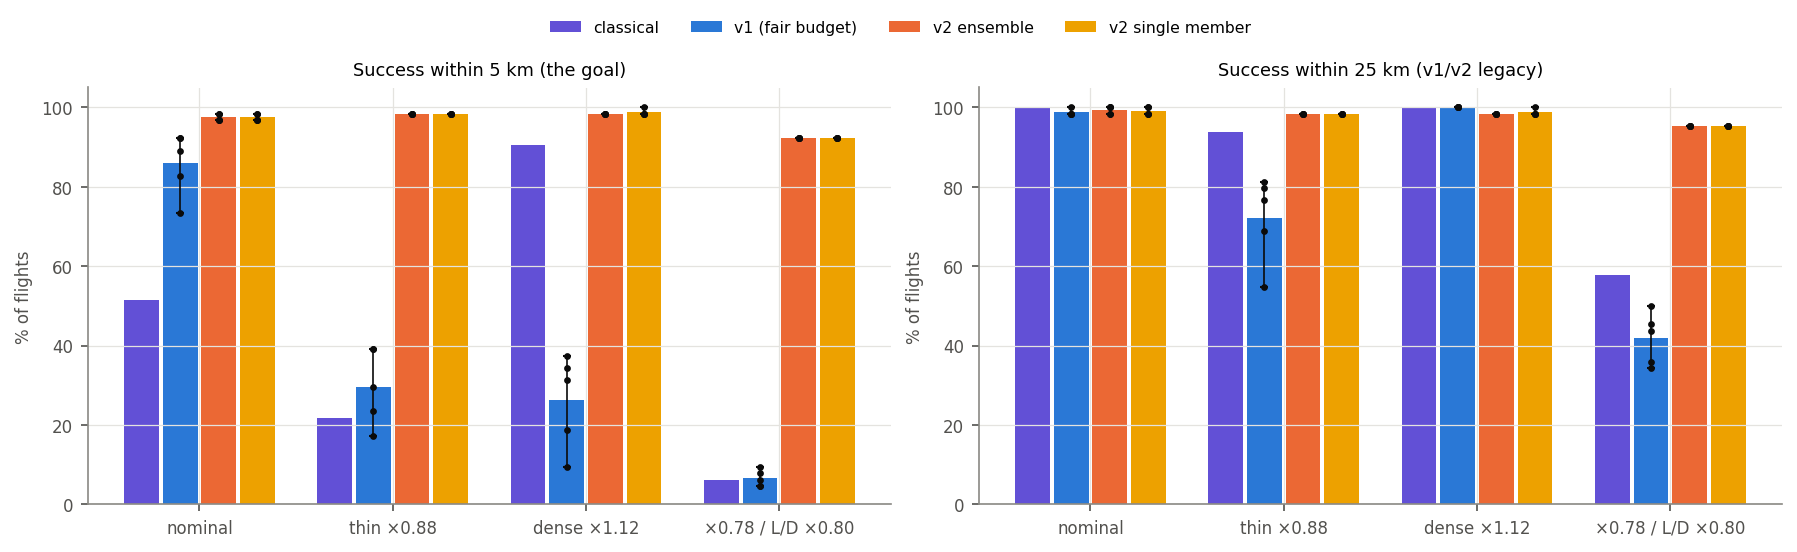

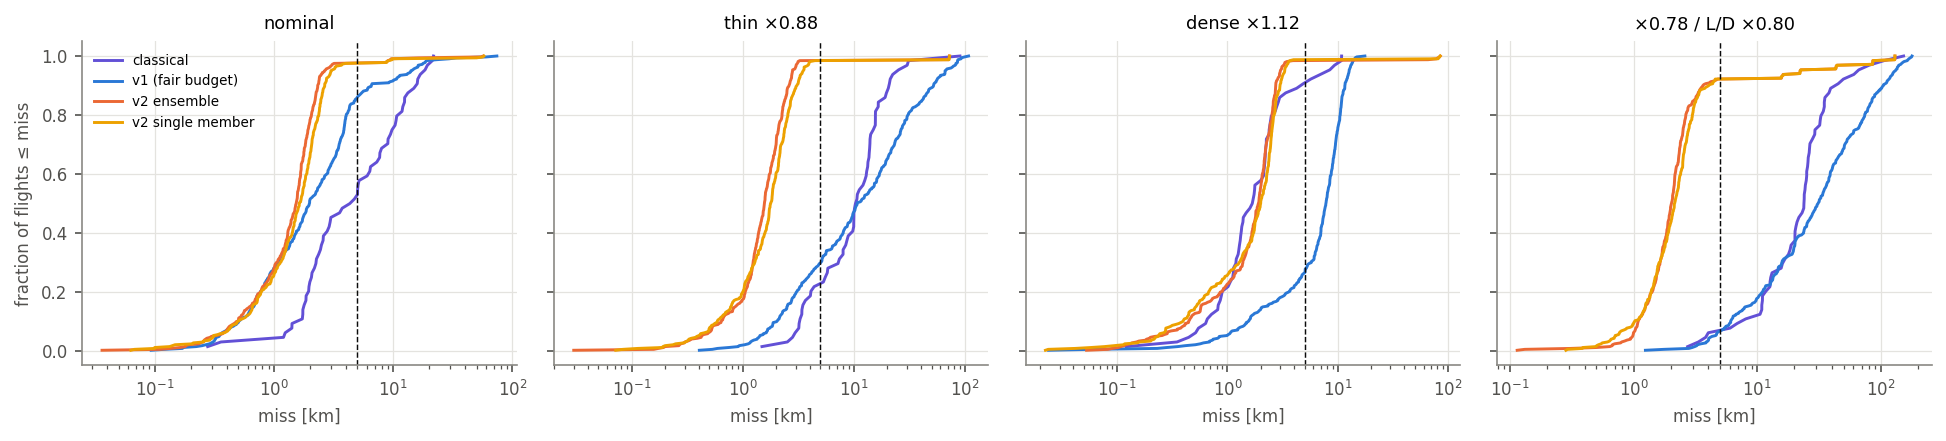

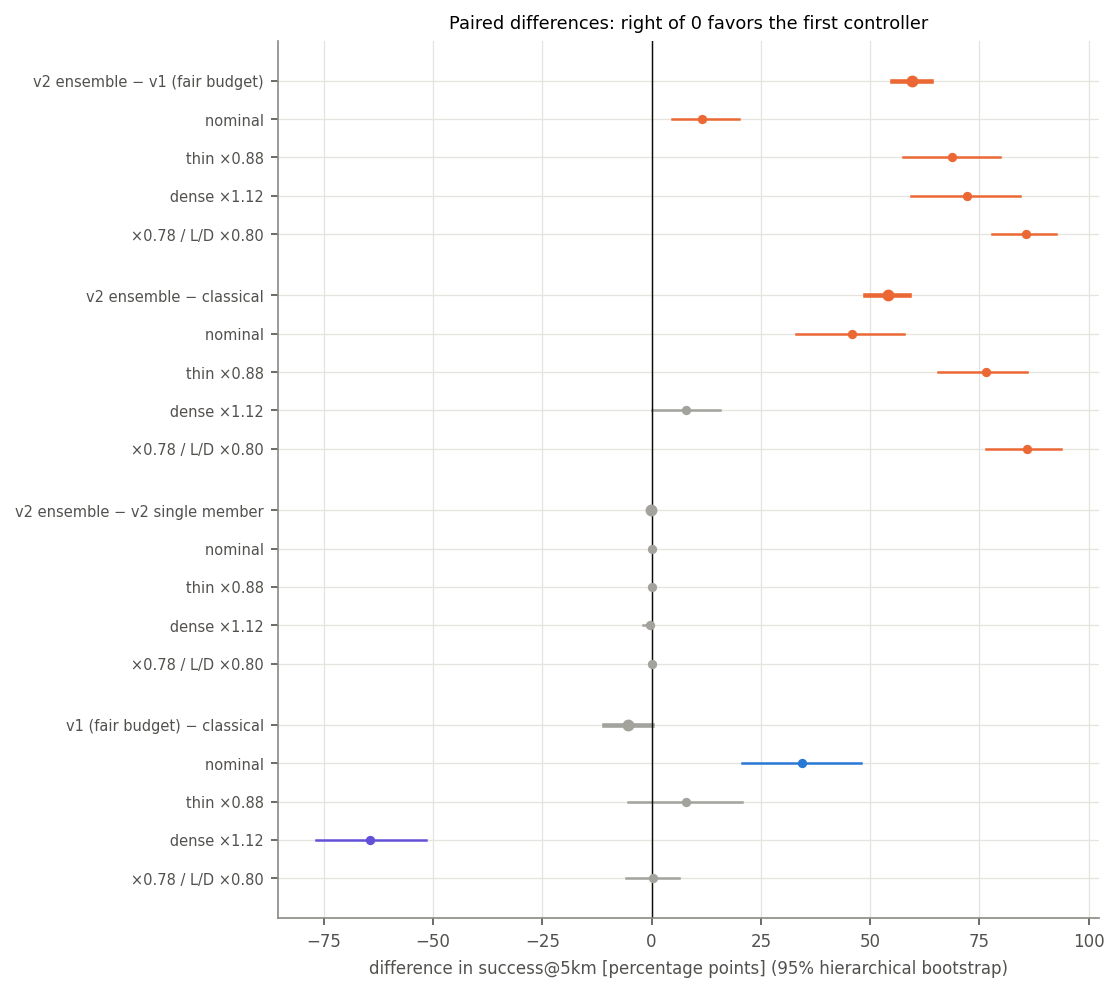

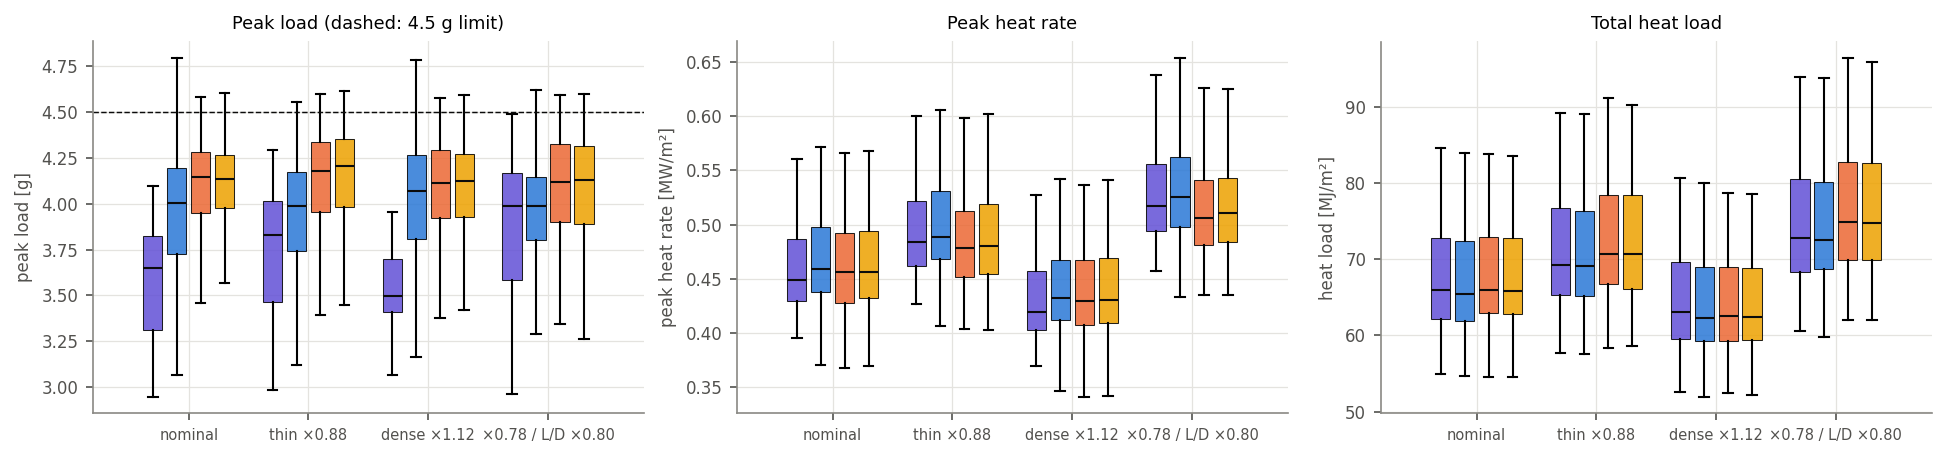

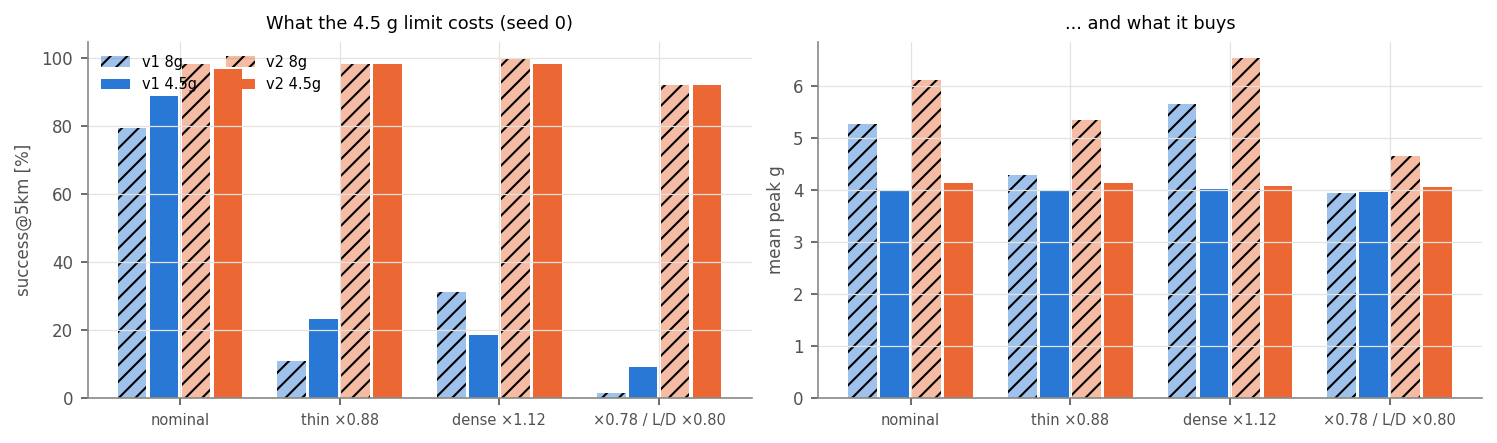

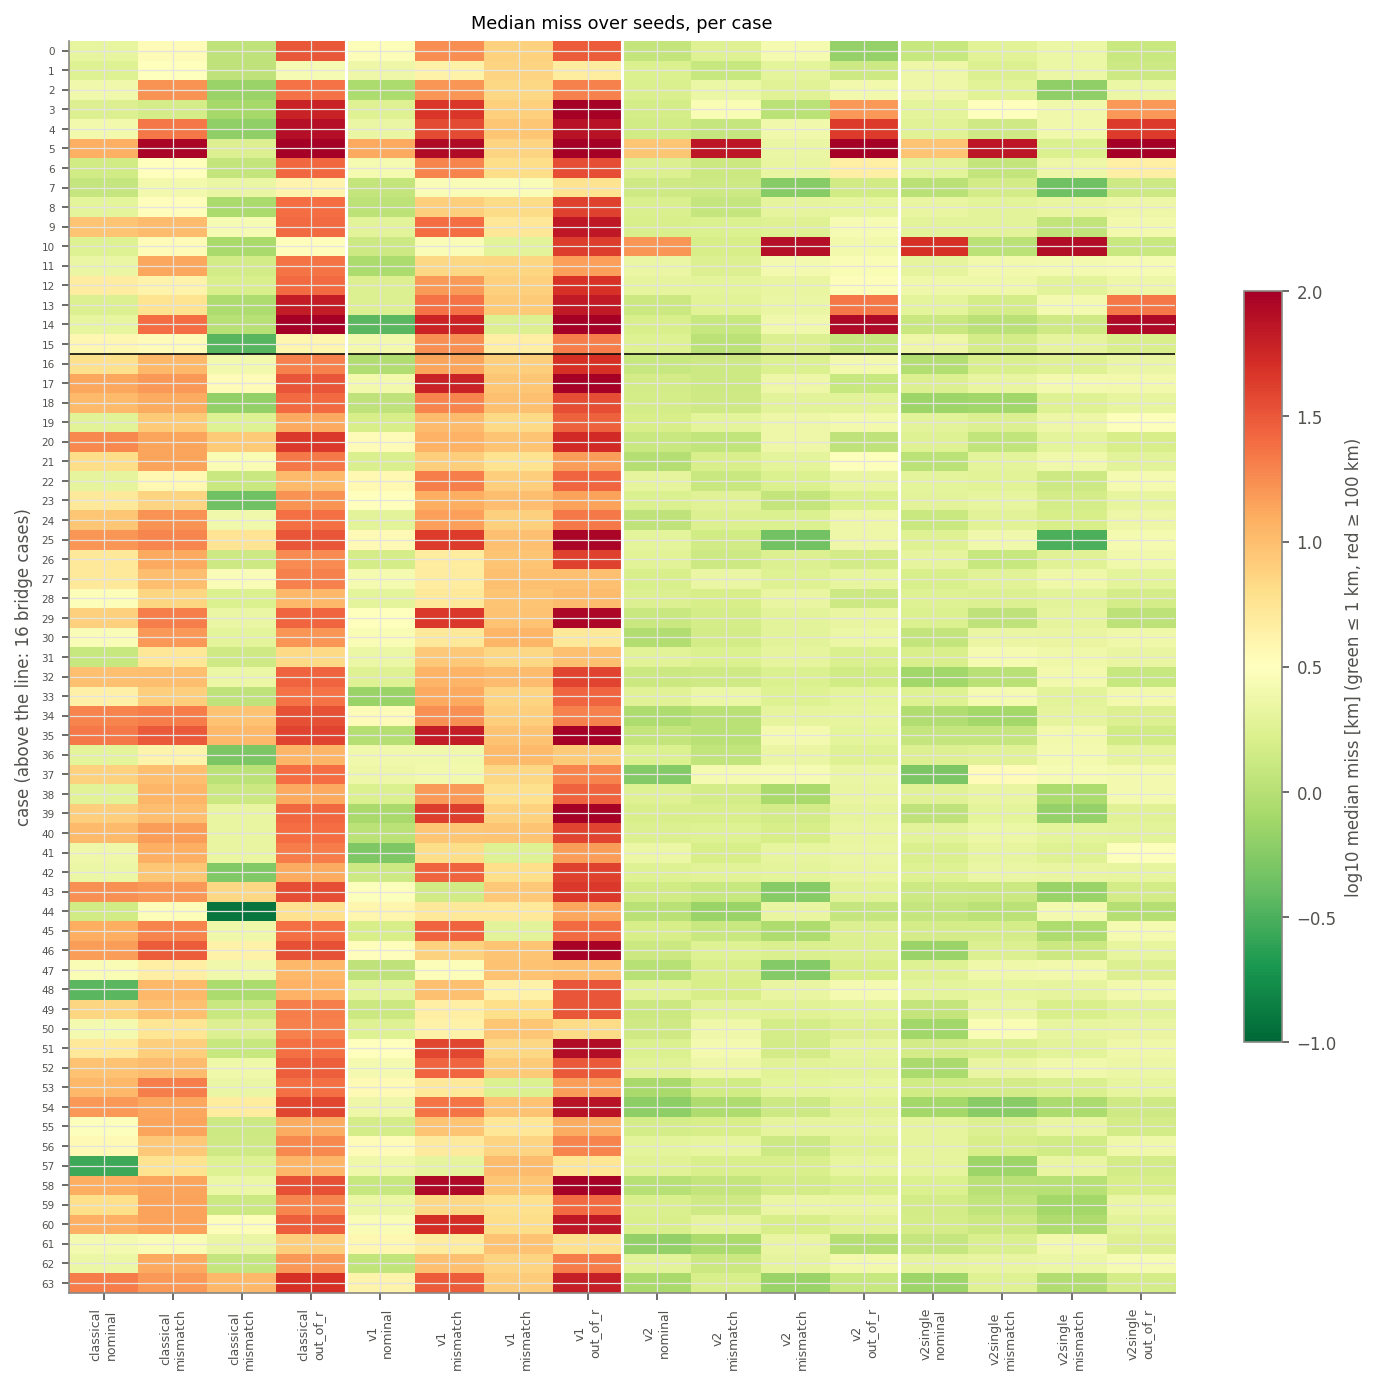

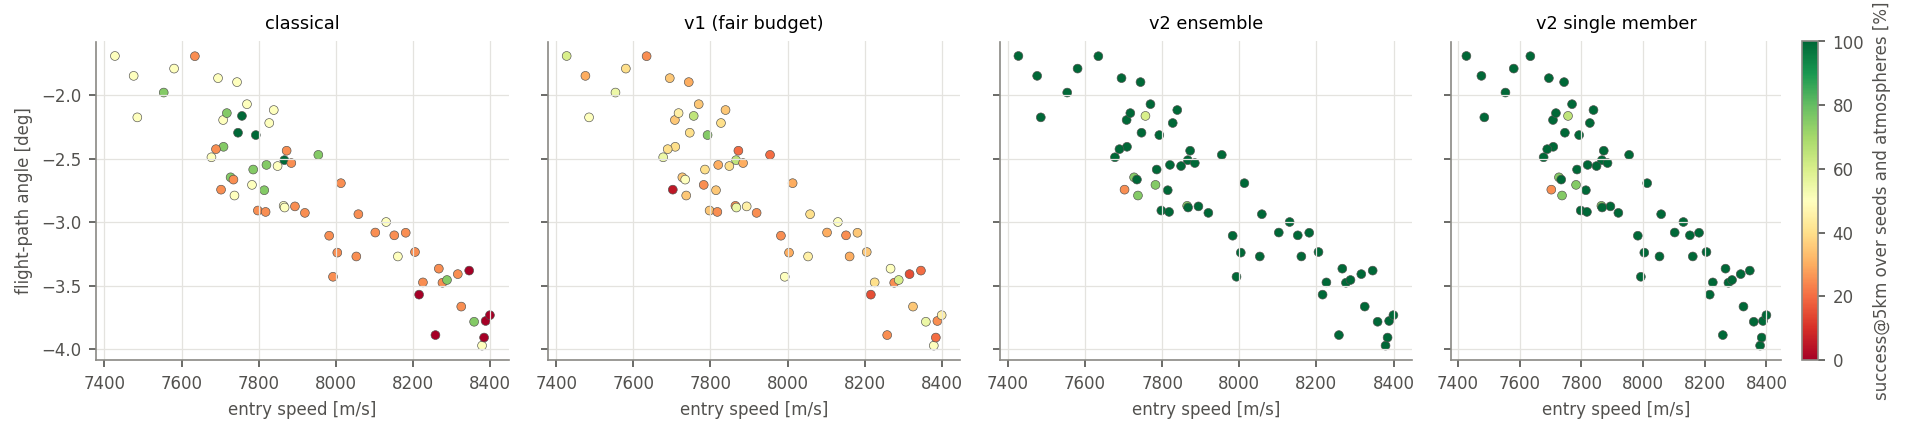

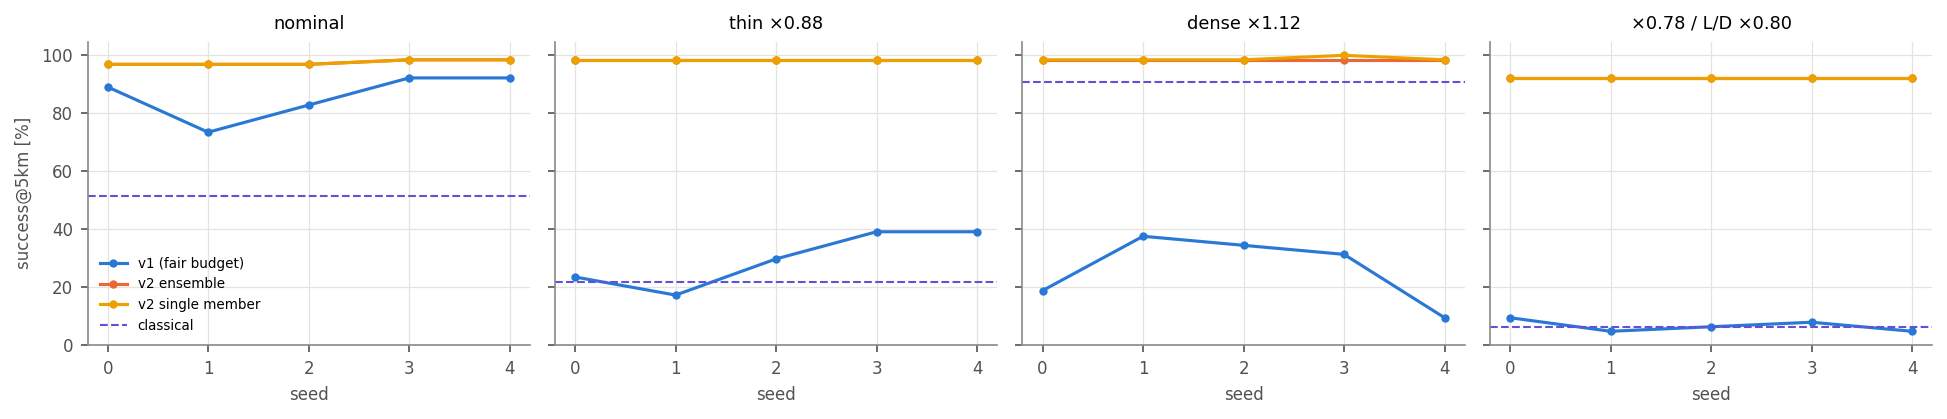

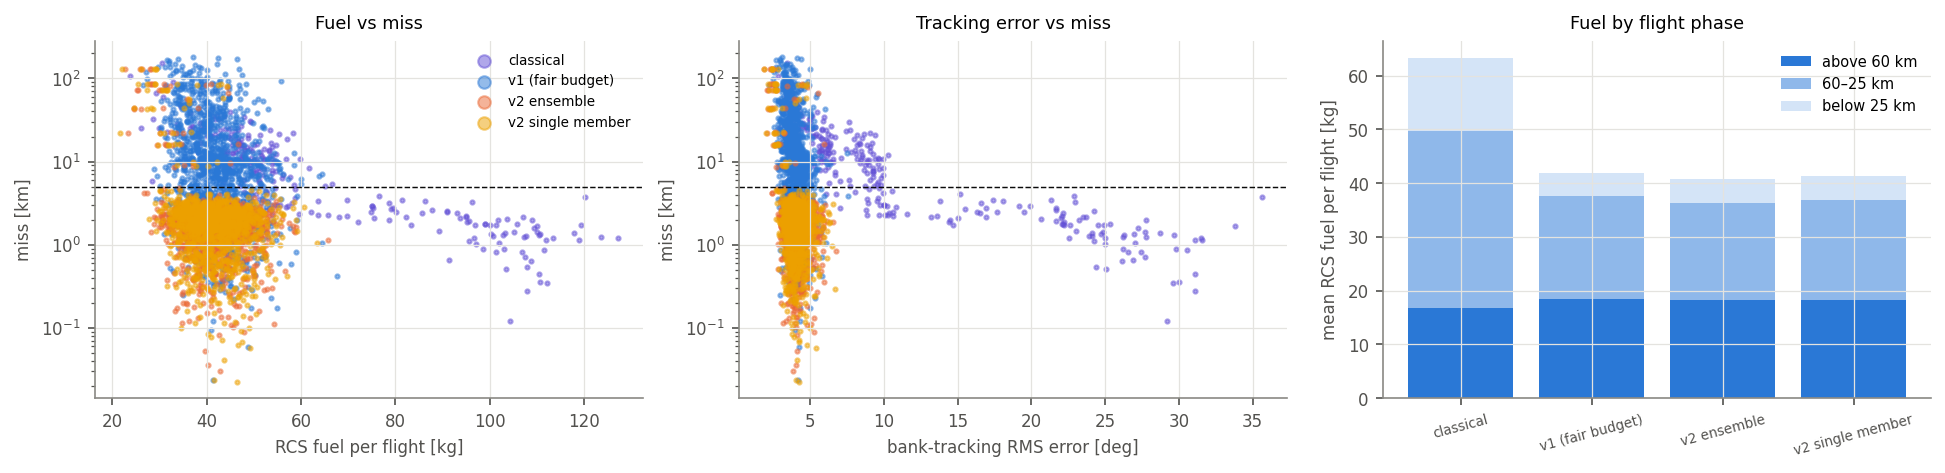

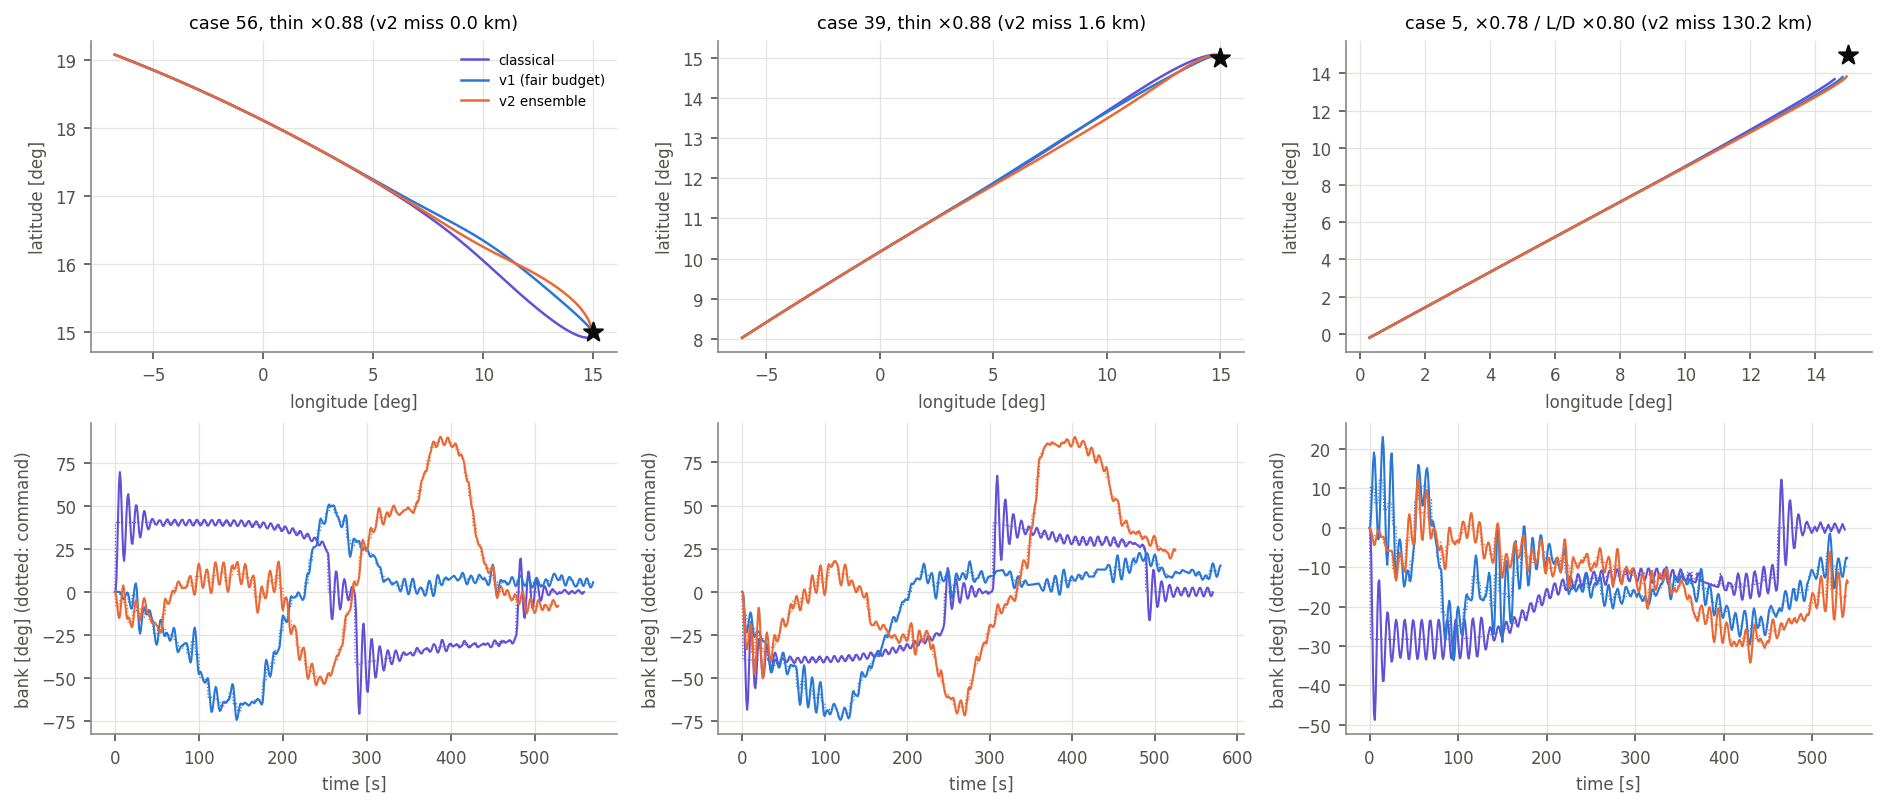

In [4]:
if R:
    cols = ["controller", "atmosphere", "n_seeds", "success5_%", "success5_%_min", "success5_%_max", "miss_median_km",
            "miss_p90_km", "peak_g_mean", "peak_qdot_MWm2_mean", "heat_load_MJm2_mean", "rcs_fuel_kg_mean"]
    display(R["T01"][cols].round(2))
    for k, p in R["figures"].items():
        display(Image(str(p)))

## 3. Report

In [ ]:
if R:
    pdf = A.build_report(CFG, L, R, OL)
    print("report:", pdf)
S.update_manifest(L)
print(open(L.study / "README.md").read())

ModuleNotFoundError: No module named 'reportlab'

[auto-disconnect] a cell failed (ModuleNotFoundError: No module named 'reportlab'). Flushing Drive and releasing the runtime; outputs stay visible.


## Done: release the runtime

Everything this notebook made is already on Drive. This cell flushes Drive and releases the Colab
runtime, so it stops using compute units (a failed cell does the same). To keep the runtime, set
`AUTO_DISCONNECT = False` in the setup cell before running.

In [ ]:
release_runtime("all cells finished")